In [ ]:
import pandas as pd

Membaca File

In [90]:
df_order_details = pd.read_csv('order_details.csv')
df_pizzas = pd.read_csv('pizzas.csv')
df_pizza_types = pd.read_csv('pizza_types.csv', encoding='latin1')

print("Semua file berhasil dimuat!")

Semua file berhasil dimuat!


Merge Sheet

In [91]:
# Load orders.csv
df_orders = pd.read_csv('orders.csv')

# 1. Gabungkan order_details dengan orders berdasarkan 'order_id'
df_merged = pd.merge(df_order_details, df_orders, on='order_id', how='left')

# 2. Gabungkan hasilnya dengan tabel pizzas berdasarkan 'pizza_id'
df_merged = pd.merge(df_merged, df_pizzas, on='pizza_id', how='left')

# 3. Gabungkan hasil terakhir dengan pizza_types berdasarkan 'pizza_type_id'
df_merged = pd.merge(df_merged, df_pizza_types, on='pizza_type_id', how='left')

# Cek 5 baris pertama dari tabel master yang baru saja digabung
print("Contoh hasil akhir setelah di-merge:")
display(df_merged.head())

Contoh hasil akhir setelah di-merge:


,order_details_id,order_id,pizza_id,quantity,date,time,pizza_type_id,size,price,name,category,ingredients
0,1,1,hawaiian_m,1,2015-01-01,11:38:36,hawaiian,M,13.25,The Hawaiian Pizza,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese"
1,2,2,classic_dlx_m,1,2015-01-01,11:57:40,classic_dlx,M,16.00,The Classic Deluxe Pizza,Classic,"Pepperoni, Mushrooms, Red Onions, Red Peppers,..."
2,3,2,five_cheese_l,1,2015-01-01,11:57:40,five_cheese,L,18.50,The Five Cheese Pizza,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go..."
3,4,2,ital_supr_l,1,2015-01-01,11:57:40,ital_supr,L,20.75,The Italian Supreme Pizza,Supreme,"Calabrese Salami, Capocollo, Tomatoes, Red Oni..."
4,5,2,mexicana_m,1,2015-01-01,11:57:40,mexicana,M,16.00,The Mexicana Pizza,Veggie,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O..."


Cek Data

In [92]:
# Cek jumlah baris dan kolom
print("Ukuran tabel master:", df_merged.shape)

# Cek apakah ada nilai yang kosong
print("\nJumlah missing values per kolom:")
print(df_merged.isnull().sum())

Ukuran tabel master: (48620, 12)

Jumlah missing values per kolom:
order_details_id    0
order_id            0
pizza_id            0
quantity            0
date                0
time                0
pizza_type_id       0
size                0
price               0
name                0
category            0
ingredients         0
dtype: int64


Buat Kolom Revenue

In [93]:
df_merged['revenue'] = df_merged['quantity'] * df_merged['price']
df_merged.head()

,order_details_id,order_id,pizza_id,quantity,date,time,pizza_type_id,size,price,name,category,ingredients,revenue
0,1,1,hawaiian_m,1,2015-01-01,11:38:36,hawaiian,M,13.25,The Hawaiian Pizza,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese",13.25
1,2,2,classic_dlx_m,1,2015-01-01,11:57:40,classic_dlx,M,16.00,The Classic Deluxe Pizza,Classic,"Pepperoni, Mushrooms, Red Onions, Red Peppers,...",16.00
2,3,2,five_cheese_l,1,2015-01-01,11:57:40,five_cheese,L,18.50,The Five Cheese Pizza,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go...",18.50
3,4,2,ital_supr_l,1,2015-01-01,11:57:40,ital_supr,L,20.75,The Italian Supreme Pizza,Supreme,"Calabrese Salami, Capocollo, Tomatoes, Red Oni...",20.75
4,5,2,mexicana_m,1,2015-01-01,11:57:40,mexicana,M,16.00,The Mexicana Pizza,Veggie,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O...",16.00


Buat Kolom Month

In [94]:
df_merged['date'] = pd.to_datetime(df_merged['date'])
df_merged['month_name'] = df_merged['date'].dt.month_name()
df_merged.head()

,order_details_id,order_id,pizza_id,quantity,date,time,pizza_type_id,size,price,name,category,ingredients,revenue,month_name
0,1,1,hawaiian_m,1,2015-01-01,11:38:36,hawaiian,M,13.25,The Hawaiian Pizza,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese",13.25,January
1,2,2,classic_dlx_m,1,2015-01-01,11:57:40,classic_dlx,M,16.00,The Classic Deluxe Pizza,Classic,"Pepperoni, Mushrooms, Red Onions, Red Peppers,...",16.00,January
2,3,2,five_cheese_l,1,2015-01-01,11:57:40,five_cheese,L,18.50,The Five Cheese Pizza,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go...",18.50,January
3,4,2,ital_supr_l,1,2015-01-01,11:57:40,ital_supr,L,20.75,The Italian Supreme Pizza,Supreme,"Calabrese Salami, Capocollo, Tomatoes, Red Oni...",20.75,January
4,5,2,mexicana_m,1,2015-01-01,11:57:40,mexicana,M,16.00,The Mexicana Pizza,Veggie,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O...",16.00,January


Buat Kolom Day

In [95]:
df_merged['date'] = pd.to_datetime(df_merged['date'])
day_name = df_merged['date'].dt.day_name()
df_merged['day_name'] = day_name
df_merged.head()

,order_details_id,order_id,pizza_id,quantity,date,time,pizza_type_id,size,price,name,category,ingredients,revenue,month_name,day_name
0,1,1,hawaiian_m,1,2015-01-01,11:38:36,hawaiian,M,13.25,The Hawaiian Pizza,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese",13.25,January,Thursday
1,2,2,classic_dlx_m,1,2015-01-01,11:57:40,classic_dlx,M,16.00,The Classic Deluxe Pizza,Classic,"Pepperoni, Mushrooms, Red Onions, Red Peppers,...",16.00,January,Thursday
2,3,2,five_cheese_l,1,2015-01-01,11:57:40,five_cheese,L,18.50,The Five Cheese Pizza,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go...",18.50,January,Thursday
3,4,2,ital_supr_l,1,2015-01-01,11:57:40,ital_supr,L,20.75,The Italian Supreme Pizza,Supreme,"Calabrese Salami, Capocollo, Tomatoes, Red Oni...",20.75,January,Thursday
4,5,2,mexicana_m,1,2015-01-01,11:57:40,mexicana,M,16.00,The Mexicana Pizza,Veggie,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O...",16.00,January,Thursday


Buat Kolom Hour

In [96]:
df_merged['hour'] = pd.to_datetime(df_merged['time'], format='%H:%M:%S').dt.hour
df_merged.head()

,order_details_id,order_id,pizza_id,quantity,date,time,pizza_type_id,size,price,name,category,ingredients,revenue,month_name,day_name,hour
0,1,1,hawaiian_m,1,2015-01-01,11:38:36,hawaiian,M,13.25,The Hawaiian Pizza,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese",13.25,January,Thursday,11
1,2,2,classic_dlx_m,1,2015-01-01,11:57:40,classic_dlx,M,16.00,The Classic Deluxe Pizza,Classic,"Pepperoni, Mushrooms, Red Onions, Red Peppers,...",16.00,January,Thursday,11
2,3,2,five_cheese_l,1,2015-01-01,11:57:40,five_cheese,L,18.50,The Five Cheese Pizza,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go...",18.50,January,Thursday,11
3,4,2,ital_supr_l,1,2015-01-01,11:57:40,ital_supr,L,20.75,The Italian Supreme Pizza,Supreme,"Calabrese Salami, Capocollo, Tomatoes, Red Oni...",20.75,January,Thursday,11
4,5,2,mexicana_m,1,2015-01-01,11:57:40,mexicana,M,16.00,The Mexicana Pizza,Veggie,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O...",16.00,January,Thursday,11


file Master

In [97]:
# Menyimpan hasil merge menjadi satu file CSV master
df_merged.to_csv('orders_full.csv', index=False)

print("File master 'orders_full.csv' berhasil dibuat dan disimpan!")

File master 'orders_full.csv' berhasil dibuat dan disimpan!


KPI

In [98]:
total_revenue = df_merged['revenue'].sum()
print("Total revenue:", total_revenue)

total_orders = df_merged['order_id'].nunique()
print("Total orders:", total_orders)

total_pizzas_sold = df_merged['quantity'].sum()
print("Total pizzas sold:", total_pizzas_sold)

AOV = total_revenue / total_orders
print("Average order value (AOV):", round(AOV, 2))

Total revenue: 817860.05
Total orders: 21350
Total pizzas sold: 49574
Average order value (AOV): 38.31


TOP 10 Pizza

Top 10 pizza by quantity:
name
The Classic Deluxe Pizza        2453
The Barbecue Chicken Pizza      2432
The Hawaiian Pizza              2422
The Pepperoni Pizza             2418
The Thai Chicken Pizza          2371
The California Chicken Pizza    2370
The Sicilian Pizza              1938
The Spicy Italian Pizza         1924
The Southwest Chicken Pizza     1917
The Big Meat Pizza              1914
Name: quantity, dtype: int64


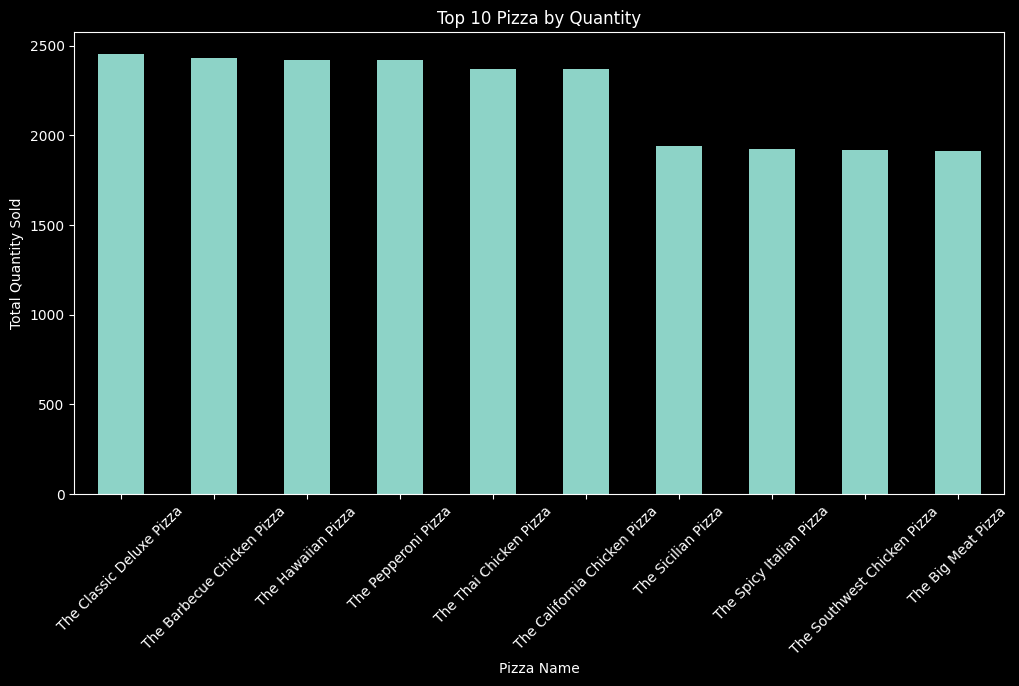


Top 10 pizza by revenue:
name
The Thai Chicken Pizza          43434.25
The Barbecue Chicken Pizza      42768.00
The California Chicken Pizza    41409.50
The Classic Deluxe Pizza        38180.50
The Spicy Italian Pizza         34831.25
The Southwest Chicken Pizza     34705.75
The Italian Supreme Pizza       33476.75
The Hawaiian Pizza              32273.25
The Four Cheese Pizza           32265.70
The Sicilian Pizza              30940.50
Name: revenue, dtype: float64


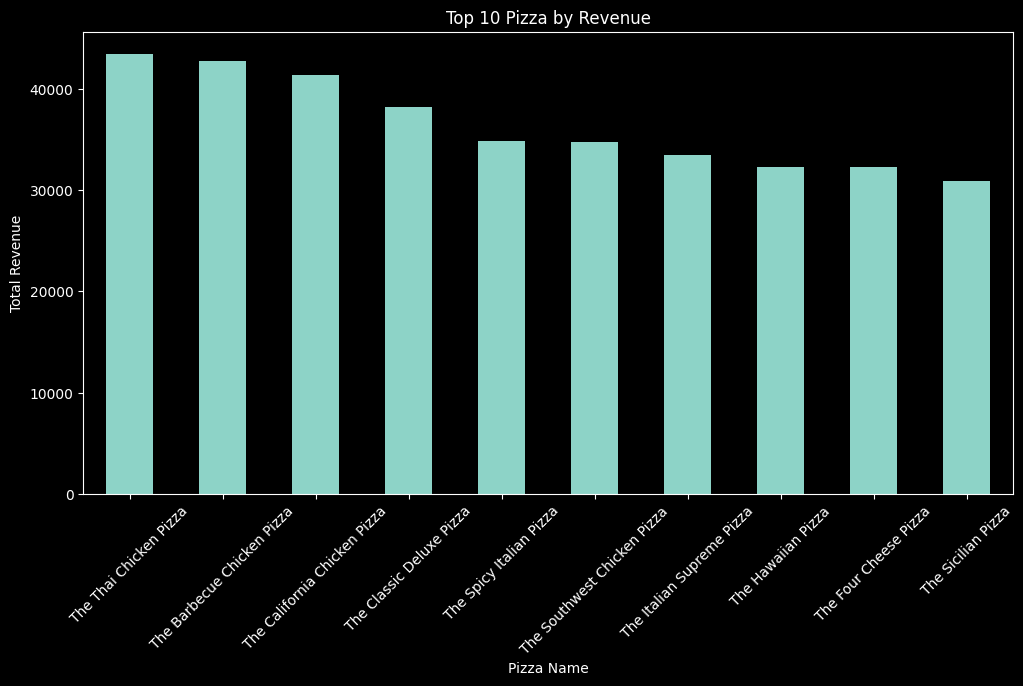

In [99]:
import matplotlib.pyplot as plt

top_10_pizza_by_quantity = df_merged.groupby('name')['quantity'].sum().sort_values(ascending=False).head(10)
print("Top 10 pizza by quantity:")
print(top_10_pizza_by_quantity)

plt.figure(figsize=(12, 6))
top_10_pizza_by_quantity.plot(kind='bar')
plt.title('Top 10 Pizza by Quantity')
plt.xlabel('Pizza Name')
plt.ylabel('Total Quantity Sold')
plt.xticks(rotation=45)
plt.show()

top_10_pizza_by_revenue = df_merged.groupby('name')['revenue'].sum().sort_values(ascending=False).head(10)
print("\nTop 10 pizza by revenue:")
print(top_10_pizza_by_revenue)

plt.figure(figsize=(12, 6))
top_10_pizza_by_revenue.plot(kind='bar')
plt.title('Top 10 Pizza by Revenue')
plt.xlabel('Pizza Name')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.show()


Hourly Trend

Hourly Trend:
        revenue  orders
hour                   
9         83.00       1
10       303.65       8
11     44935.80    1231
12    111877.90    2520
13    106065.70    2455
14     59201.40    1472
15     52992.30    1468
16     70055.40    1920
17     86237.45    2336
18     89296.85    2399
19     72628.90    2009
20     58215.40    1642
21     42029.80    1198
22     22815.15     663
23      1121.35      28


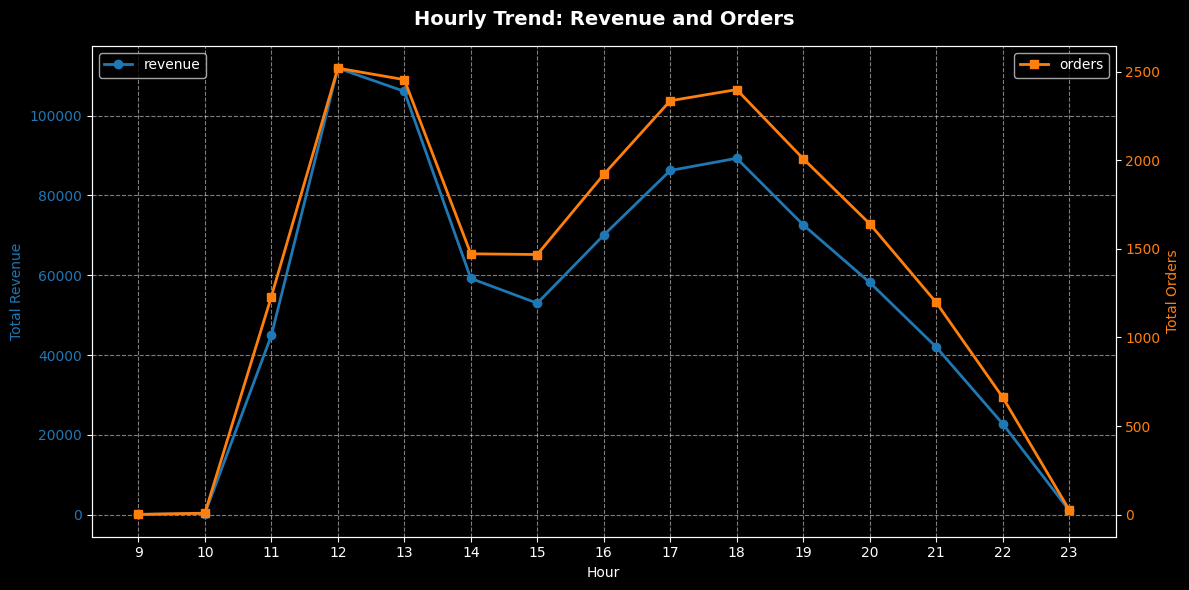

In [100]:
import matplotlib.pyplot as plt

hourly_trend = df_merged.groupby('hour').agg(
    revenue=('revenue', 'sum'),
    orders=('order_id', 'nunique')
)

print("Hourly Trend:")
print(hourly_trend)

# Membuat figure
fig, ax1 = plt.subplots(figsize=(12, 6))

hourly_trend['revenue'].plot(kind='line', marker='o', color='tab:blue', ax=ax1, legend=True, linewidth=2)
ax1.set_ylabel('Total Revenue', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
hourly_trend['orders'].plot(kind='line', marker='s', color='tab:orange', ax=ax2, legend=True, linewidth=2)
ax2.set_ylabel('Total Orders', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')
ax2.grid(False)

plt.title('Hourly Trend: Revenue and Orders', fontsize=14, fontweight='bold', pad=15)
ax1.set_xlabel('Hour')
ax1.set_xticks(hourly_trend.index)
ax1.grid(True, linestyle='--', alpha=0.5)

ax1.legend(loc='upper left')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

Monthly Trend

Monthly Trend:
             revenue  quantity
month_name                    
January     69793.30      4232
February    65159.60      3961
March       70397.10      4261
April       68736.80      4151
May         71402.75      4328
June        68230.20      4107
July        72557.90      4392
August      68278.25      4168
September   64180.05      3890
October     64027.60      3883
November    70395.35      4266
December    64701.15      3935


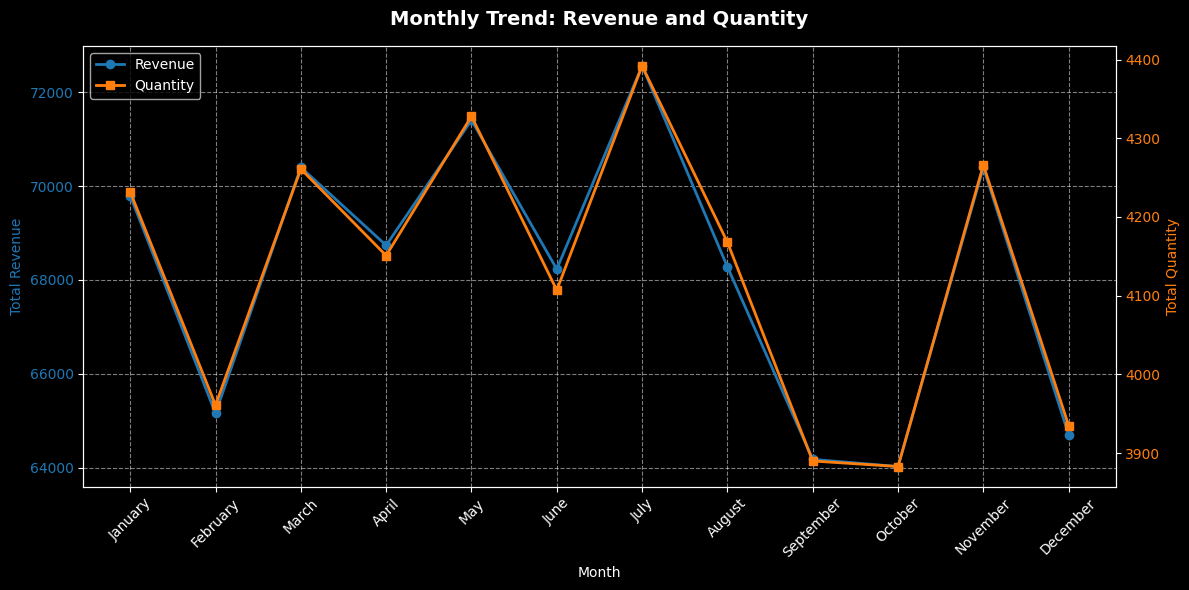

In [101]:
import matplotlib.pyplot as plt

monthly_trend = df_merged.groupby('month_name').agg(
    revenue=('revenue', 'sum'),
    quantity=('quantity', 'sum')
)

# Urutan bulan kalender
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_trend = monthly_trend.reindex(
    [m for m in month_order if m in monthly_trend.index]
)

print("Monthly Trend:")
print(monthly_trend)

# Membuat figure
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(
    range(len(monthly_trend)),
    monthly_trend['revenue'],
    marker='o',
    color='tab:blue',
    linewidth=2,
    label='Revenue'
)

ax1.set_ylabel('Total Revenue', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.set_xlabel('Month')
ax1.set_xticks(range(len(monthly_trend)))
ax1.set_xticklabels(monthly_trend.index, rotation=45)
ax1.grid(True, linestyle='--', alpha=0.5)

ax2 = ax1.twinx()
ax2.plot(
    range(len(monthly_trend)),
    monthly_trend['quantity'],
    marker='s',
    color='tab:orange',
    linewidth=2,
    label='Quantity'
)

ax2.set_ylabel('Total Quantity', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')
ax2.grid(False)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc='upper left'
)

plt.title(
    'Monthly Trend: Revenue and Quantity',
    fontsize=14,
    fontweight='bold',
    pad=15
)

plt.tight_layout()
plt.show()

Daily Trend

Daily Trend:
             revenue  quantity
day_name                      
Sunday      99203.50      6035
Monday     107329.55      6485
Tuesday    114133.80      6895
Wednesday  114408.40      6946
Thursday   123528.50      7478
Friday     136073.90      8242
Saturday   123182.40      7493


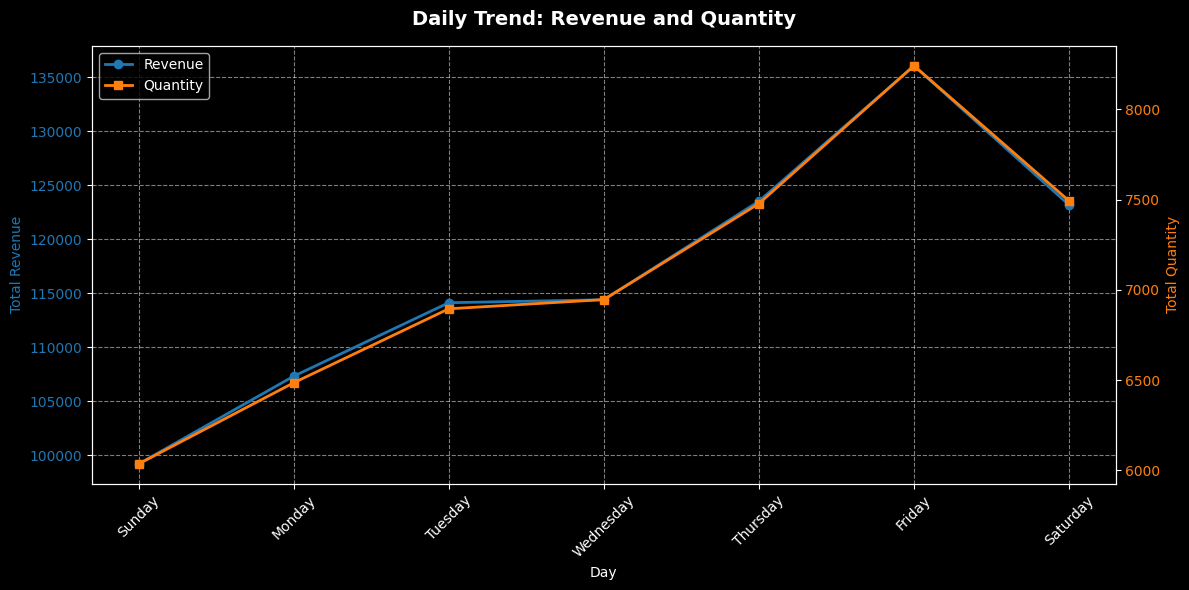

In [102]:
import matplotlib.pyplot as plt

daily_trend = df_merged.groupby('day_name').agg(
    revenue=('revenue', 'sum'),
    quantity=('quantity', 'sum')
)

day_order = [
    'Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday'
]

daily_trend = daily_trend.reindex(
    [d for d in day_order if d in daily_trend.index]
)

print("Daily Trend:")
print(daily_trend)

fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(
    range(len(daily_trend)),
    daily_trend['revenue'],
    marker='o',
    color='tab:blue',
    linewidth=2,
    label='Revenue'
)

ax1.set_ylabel('Total Revenue', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.set_xlabel('Day')
ax1.set_xticks(range(len(daily_trend)))
ax1.set_xticklabels(daily_trend.index, rotation=45)
ax1.grid(True, linestyle='--', alpha=0.5)

ax2 = ax1.twinx()
ax2.plot(
    range(len(daily_trend)),
    daily_trend['quantity'],
    marker='s',
    color='tab:orange',
    linewidth=2,
    label='Quantity'
)

ax2.set_ylabel('Total Quantity', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')
ax2.grid(False)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc='upper left'
)

plt.title(
    'Daily Trend: Revenue and Quantity',
    fontsize=14,
    fontweight='bold',
    pad=15
)

plt.tight_layout()
plt.show()

Category Performance

Category Performance:
          total_revenue  total_quantity
category                               
Chicken       195919.50           11050
Classic       220053.10           14888
Supreme       208197.00           11987
Veggie        193690.45           11649


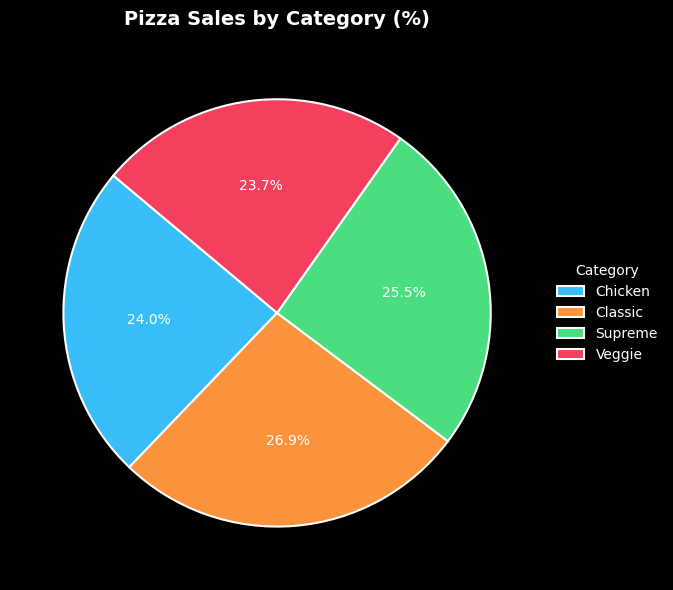

In [103]:
category_performance = df_merged.groupby('category').agg(
    total_revenue=('revenue', 'sum'),
    total_quantity=('quantity', 'sum')
)

print("Category Performance:")
print(category_performance)

plt.figure(figsize=(9, 6))
wedges, texts, autotexts = plt.pie(
    category_performance['total_revenue'],
    autopct='%1.1f%%',
    startangle=140,
    colors=['#38bdf8', '#fb923c', '#4ade80', '#f43f5e'],
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)

plt.legend(
    wedges, category_performance.index,
    title="Category",
    loc="center left",
    bbox_to_anchor=(1, 0, 0.5, 1),
    frameon=False
)

plt.title('Pizza Sales by Category (%)', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

Size Performance

Size Performance:
      total_revenue  total_quantity
size                               
L         375318.70           18956
M         249382.25           15635
S         178076.50           14403
XL         14076.00             552
XXL         1006.60              28


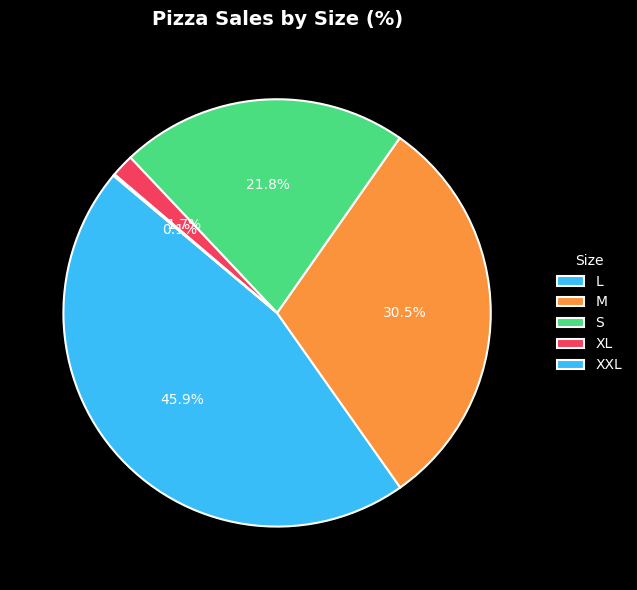

In [104]:
size_performance = df_merged.groupby('size').agg(
    total_revenue=('revenue', 'sum'),
    total_quantity=('quantity', 'sum')
)

print("Size Performance:")
print(size_performance)

plt.figure(figsize=(9, 6))
wedges, texts, autotexts = plt.pie(
    size_performance['total_revenue'],
    autopct='%1.1f%%',
    startangle=140,
    colors=['#38bdf8', '#fb923c', '#4ade80', '#f43f5e'],
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)

plt.legend(
    wedges, size_performance.index,
    title="Size",
    loc="center left",
    bbox_to_anchor=(1, 0, 0.5, 1),
    frameon=False
)

plt.title('Pizza Sales by Size (%)', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()